TensorFlow: 2.21.0
Total RAM: 13.86 GB
Available RAM: 5.19 GB
TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
# Core libraries
import os
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import kagglehub

print("TensorFlow:", tf.__version__)
print("Python executable:", __import__("sys").executable)

TensorFlow: 2.21.0
Python executable: c:\Users\Prateek Verma\OneDrive\Desktop\PDP\.venv\Scripts\python.exe


In [3]:
import tensorflow as tf

result = tf.reduce_sum(tf.ones([3, 3])).numpy()
print("Test result:", result)

import kagglehub
print("KaggleHub is ready!")

Test result: 9.0
KaggleHub is ready!


In [4]:
# Download the PlantVillage dataset using KaggleHub.
path = kagglehub.dataset_download("emmarex/plantdisease")
print("Downloaded dataset path:", path)

Downloaded dataset path: C:\Users\Prateek Verma\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1


In [5]:
# Inspect the download's top-level contents before choosing the image directory.
print(os.listdir(path))

['PlantVillage']


In [6]:
# Resolve the actual class-folder root.
# Some downloads contain an extra PlantVillage/PlantVillage nesting level.
root = Path(path)

if (root / "PlantVillage").is_dir():
    root = root / "PlantVillage"

nested_root = root / "PlantVillage"
if nested_root.is_dir():
    nested_class_dirs = [
        p for p in nested_root.iterdir()
        if p.is_dir() and any(
            f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
            for f in p.rglob("*")
        )
    ]
    # Use the nested directory only if it contains actual image-bearing class folders.
    if len(nested_class_dirs) >= 2:
        root = nested_root

data_dir = str(root)
print("Selected dataset root:", Path(data_dir).resolve())

Selected dataset root: C:\Users\Prateek Verma\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1\PlantVillage\PlantVillage


In [7]:
# Verify class folders and image counts before training.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_dirs = sorted(p for p in Path(data_dir).iterdir() if p.is_dir())
print("Number of top-level folders:", len(class_dirs))

for folder in class_dirs:
    count = sum(
        1 for f in folder.rglob("*")
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"{folder.name}: {count} images")

assert len(class_dirs) >= 2, (
    "The selected data_dir does not contain at least two class folders. "
    "Check the printed path and folder listing before continuing."
)

Number of top-level folders: 15
Pepper__bell___Bacterial_spot: 997 images
Pepper__bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___healthy: 152 images
Potato___Late_blight: 1000 images
Tomato__Target_Spot: 1404 images
Tomato__Tomato_mosaic_virus: 373 images
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_healthy: 1591 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images


In [8]:
# Image size and batch size
IMG_SIZE = 224
BATCH_SIZE = 8
SEED = 123

In [9]:
# Load the training split. Keep the same seed for a reproducible split.
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.


In [10]:
# Load the validation split using the exact same class ordering and seed.
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 20638 files belonging to 15 classes.
Using 4127 files for validation.


In [11]:
# TensorFlow derives labels from folder names. Save this exact order for the app.
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)
for i, name in enumerate(class_names):
    print(i, name)

assert NUM_CLASSES == len(class_dirs), (
    "TensorFlow's detected classes do not match the top-level class folders."
)

Number of classes: 15
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy


In [12]:
# Cache and prefetch improve input-pipeline performance.
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

InvalidArgumentError: {{function_node __wrapped__StridedSlice_device_/job:localhost/replica:0/task:0/device:CPU:0}} slice index 8 of dimension 0 out of bounds. [Op:StridedSlice] name: strided_slice/

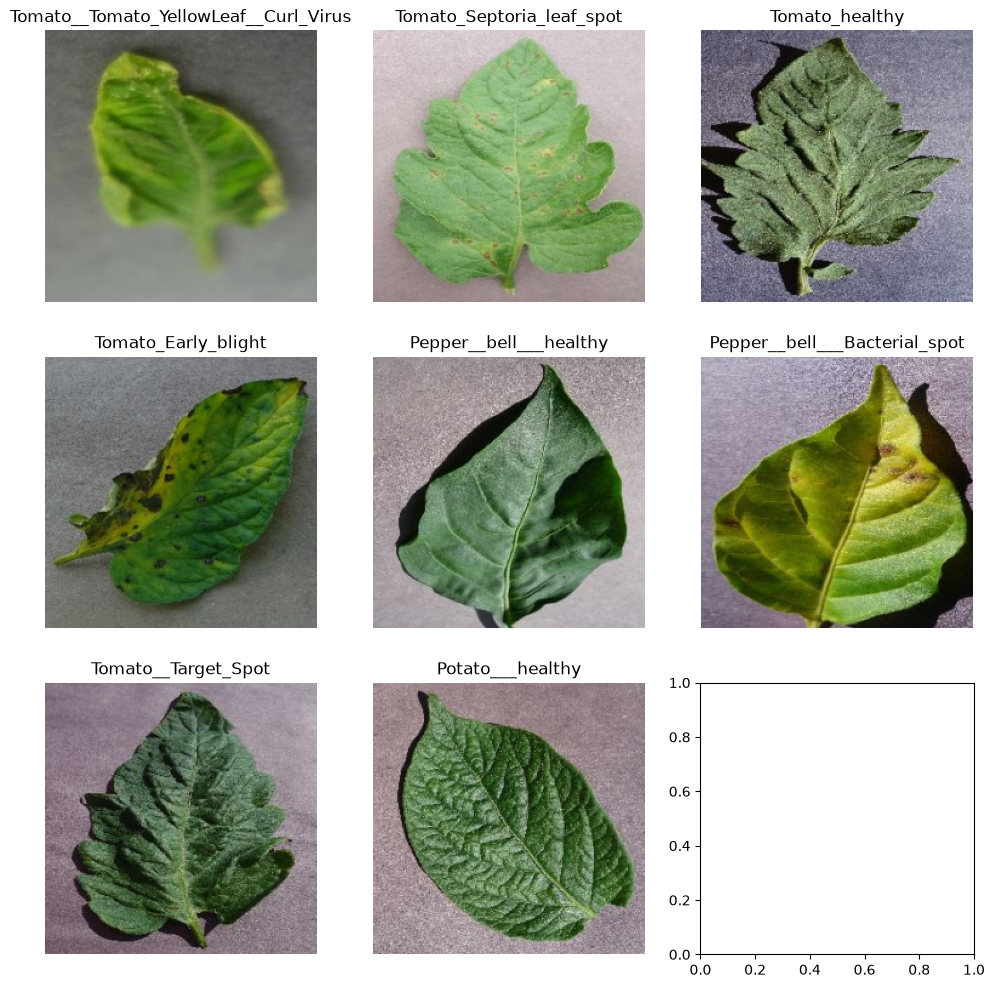

In [13]:
# Dataset se ek batch lekar kuch sample images display karenge.
# Isse verify ho jayega ki images aur labels sahi load hue hain.

plt.figure(figsize=(12, 12))

for images, labels in train_ds.take(1):

    # First 9 images display karenge.
    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        # Image show karega.
        plt.imshow(images[i].numpy().astype("uint8"))

        # Image ka class name title me show karega.
        plt.title(class_names[labels[i]])

        # Axis hide kar denge taaki image clean dikhe.
        plt.axis("off")
        

In [14]:
# Moderate augmentation: applied only during training.
# Input pixels are still in the 0..255 range at this point.
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

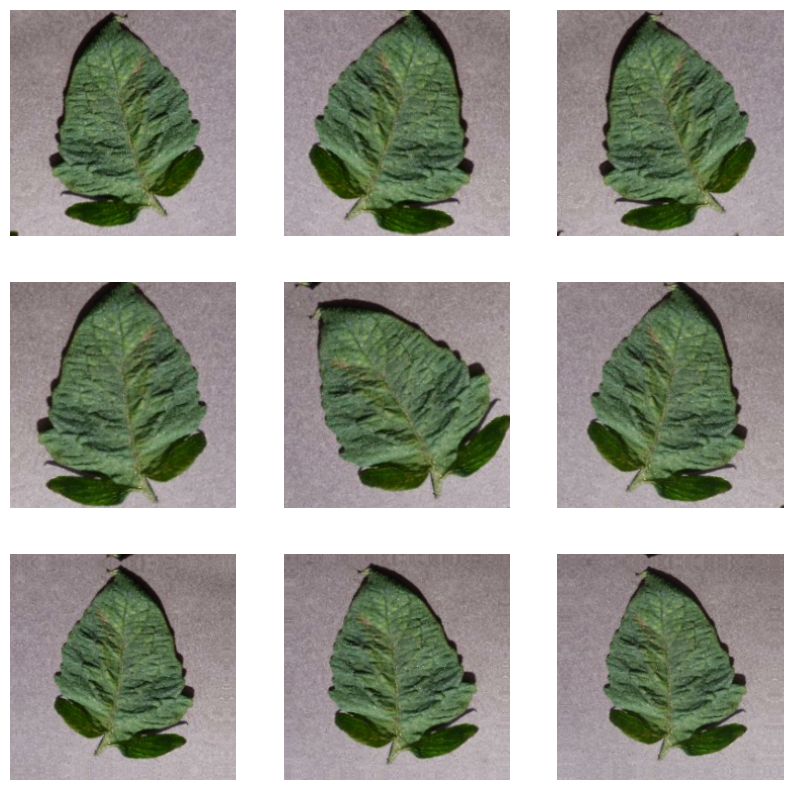

In [15]:
# Ek image ke different augmented versions dekhte hain.

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    first_image = images[0]

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        # Training=True likhne se augmentation apply hogi.
        augmented_image = data_augmentation(
            tf.expand_dims(first_image,0),
            training=True
        )

        plt.imshow(augmented_image[0].numpy().astype("uint8"))

        plt.axis("off")
        

In [16]:
# MobileNetV2 pretrained weights expect RGB pixels scaled from 0..255 to -1..1.
# This replaces the old Rescaling(1./255), which was mismatched to MobileNetV2.
mobilenet_preprocess = layers.Rescaling(1.0 / 127.5, offset=-1)

In [17]:
# Verify the preprocessing range used by MobileNetV2.
for images, labels in train_ds.take(1):
    processed = mobilenet_preprocess(images)
    print("Minimum pixel value:", float(tf.reduce_min(processed)))
    print("Maximum pixel value:", float(tf.reduce_max(processed)))
    break

Minimum pixel value: -1.0
Maximum pixel value: 0.9565039873123169


In [18]:
# Transfer Learning ek Deep Learning technique hai.

# Normally agar hum CNN model scratch se banaye,
# to hume lakhon images aur bahut zyada training time chahiye hota hai.

# Lekin Transfer Learning me hum ek aisa model use karte hain
# jo pehle se hi bahut bade dataset (ImageNet) par train ho chuka hota hai.

# ImageNet me lagbhag 14 million images aur 1000 classes hoti hain.

# Isliye model pehle hi important features jaise
# Edges, Shapes, Colors aur Textures seekh chuka hota hai.

# Ab hume sirf apne Plant Disease dataset ke according
# model ko thoda sa train (Fine Tune) karna hota hai.

# Fayde:
# ✅ Kam training time
# ✅ Kam data me bhi achhi accuracy
# ✅ Better performance

In [19]:
# Load the ImageNet-pretrained MobileNetV2 feature extractor.
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

In [20]:
# Keep the pretrained backbone frozen for the first training stage.
base_model.trainable = False

In [21]:
# MobileNetV2 image ko directly disease nahi batata.
# Ye image se important features nikalta hai jaise
# →
# Edges
# →
# Corners
# →
# Shapes
# →
# Leaf Texture
# →
# Disease Spots
# →
# Color Patterns

# In sab features ko Feature Maps kehte hain.
# Baad me humari Dense Layers in features ko use karke
# disease predict karti hain.

In [22]:
# Build the classifier with MobileNetV2-compatible preprocessing.
# training=False keeps BatchNormalization statistics in inference mode,
# including during fine-tuning.
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="leaf_image")
x = data_augmentation(inputs)
x = mobilenet_preprocess(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="disease_probabilities")(x)

model = models.Model(inputs, outputs, name="plant_disease_mobilenetv2")

In [23]:
# Model ki architecture dekhne ke liye.
# Isme har layer ka
# →
# Output Shape
# →
# Parameters
# →
# Trainable Parameters
# →
# Non-Trainable Parameters
# show honge.

model.summary()

Model: "plant_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_probabilities (Dense)   │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625,871 (10.02 MB)

 Trainable params: 365,327 (1.39 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [24]:
# Compile the feature-extraction stage.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_plant_disease_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [25]:
# Stage 1: train the new classification head while MobileNetV2 is frozen.
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


c:\Users\Prateek Verma\OneDrive\Desktop\PDP\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2064/2064 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.6921 - loss: 0.9878
Epoch 1: val_accuracy improved from None to 0.94936, saving model to best_plant_disease_model.keras

Epoch 1: finished saving model to best_plant_disease_model.keras
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 441s 211ms/step - accuracy: 0.6921 - loss: 0.9878 - val_accuracy: 0.9494 - val_loss: 0.1675 - learning_rate: 0.0010
Epoch 2/15
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.7835 - loss: 0.6872
Epoch 2: val_accuracy did not improve from 0.94936
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 592s 287ms/step - accuracy: 0.7835 - loss: 0.6872 - val_accuracy: 0.9295 - val_loss: 0.2054 - learning_rate: 0.0010
Epoch 3/15
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.8069 - loss: 0.6050
Epoch 3: val_accuracy improved from 0.94936 to 0.95008, saving model to best_plant_disease_model.keras

Epoch 3: finished saving model to best_plant_disease_model.keras

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00030

In [26]:
# History object ke andar kaun-kaun si values store hui hain
# wo dekhne ke liye.

print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


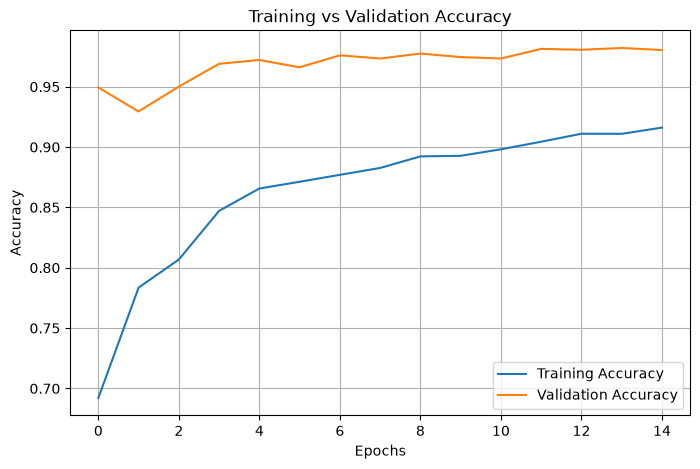

In [27]:
# Training aur Validation Accuracy graph plot kar rahe hain.

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

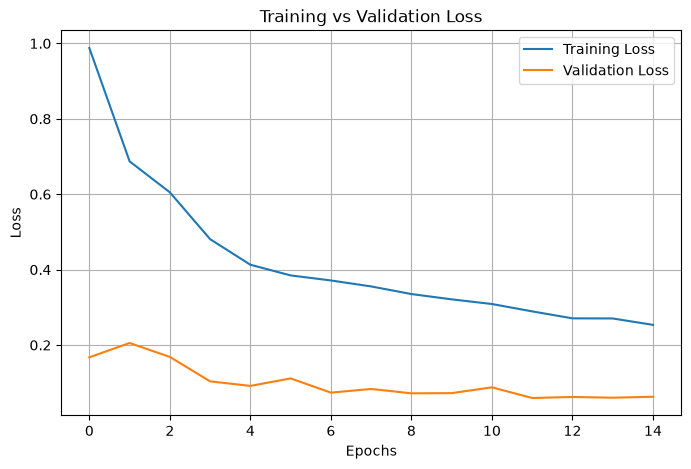

In [28]:
# Training aur Validation Loss graph plot kar rahe hain.

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [29]:
# Fine-tuning: unfreeze only the last part of MobileNetV2.
# BatchNormalization layers remain frozen for more stable transfer learning.

In [30]:
base_model.trainable = True

# Freeze earlier layers and allow the last 30 layers to adapt.
for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [31]:
# Use a very small learning rate for fine-tuning.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [32]:
# Stage 2: fine-tune with early stopping and checkpointing.
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.9065 - loss: 0.2787
Epoch 1: val_accuracy improved from 0.98207 to 0.98255, saving model to best_plant_disease_model.keras

Epoch 1: finished saving model to best_plant_disease_model.keras
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 548s 262ms/step - accuracy: 0.9065 - loss: 0.2787 - val_accuracy: 0.9826 - val_loss: 0.0576 - learning_rate: 1.0000e-05
Epoch 2/10
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9190 - loss: 0.2475
Epoch 2: val_accuracy did not improve from 0.98255
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 534s 259ms/step - accuracy: 0.9190 - loss: 0.2475 - val_accuracy: 0.9622 - val_loss: 0.1297 - learning_rate: 1.0000e-05
Epoch 3/10
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - accuracy: 0.9233 - loss: 0.2331
Epoch 3: val_accuracy improved from 0.98255 to 0.98498, saving model to best_plant_disease_model.keras

Epoch 3: finished saving model to best_plant_disease_model.keras
2064/2064 ━━━━━━━━━━━━━━━━━━━━ 571s 263

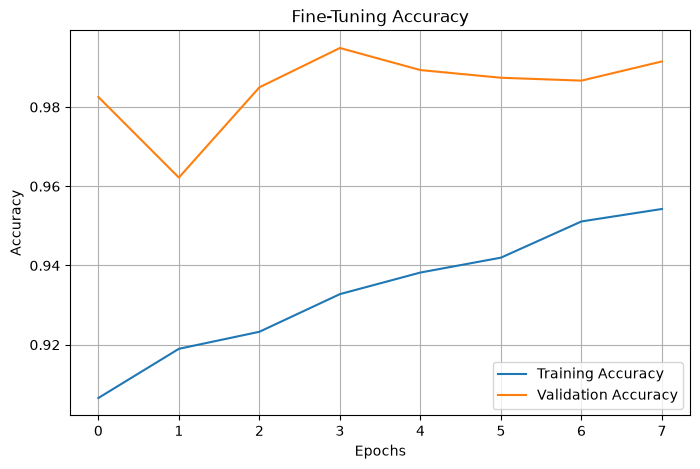

In [33]:
# Fine-Tuning ke baad accuracy graph dekhte hain.

plt.figure(figsize=(8,5))

plt.plot(history_fine.history["accuracy"], label="Training Accuracy")

plt.plot(history_fine.history["val_accuracy"], label="Validation Accuracy")

plt.title("Fine-Tuning Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

In [34]:
# Save the best validation model and the exact class order used during training.
# EarlyStopping restores the best weights for the final training stage.
model.save("plant_disease_model.keras")
print("Saved model: plant_disease_model.keras")

Saved model: plant_disease_model.keras


In [35]:
# The app must load this file; its order matches the model's output indices.
np.save("class_names.npy", np.array(class_names))
print("Saved class labels:", len(class_names))

Saved class labels: 15


In [36]:
# Verify that both deployment files exist.
print("Model exists:", os.path.exists("plant_disease_model.keras"))
print("Class names exist:", os.path.exists("class_names.npy"))
print("Class names:", np.load("class_names.npy", allow_pickle=True).tolist())

Model exists: True
Class names exist: True
Class names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [37]:
import os
print(os.path.getsize("plant_disease_model.keras") / (1024 * 1024), "MB")

24.93630027770996 MB
